In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from behavior_fw.io.load_dataset import load_experiment_dataset
from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition

from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.analysis.calc_velocities import get_velocities
# from behavior_fw.visualization.plot_density import (
#     plot_dynamic_cartesian_densities,
#     plot_dynamic_polar_densities,
# )
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)
from behavior_fw.visualization.plot_trajectory import plot_single_fly_trajectory, plot_multi_experiment_split_trajectories

In [2]:
path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 

In [3]:
path_to_metadata = path_dir_dataset / "metadata.csv"
df_metadata = pd.read_csv(path_to_metadata,index_col=0 )
df_metadata

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium,center
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR,300
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR,300
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,95930,2026-08-15 9:59:30,Gr43a,OptoCL,ATR,300
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR,300
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR,300
...,...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR,300
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR,300
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR,300
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR,300


In [4]:
df_Gr5a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="ATR", zone="300")
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="300")
df_Gr5a_NR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="NR", zone="300")
df_Gr43a_NR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="300")
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset_Gr5a_ATR_CL = load_experiment_dataset(df_Gr5a_ATR_CL, fps=60.0)
print(f"Loaded {len(dataset_Gr5a_ATR_CL)} flies into memory!")
print("Columns in df_track:", dataset_Gr5a_ATR_CL[0]["df_track"].columns.tolist())

dataset_Gr43a_ATR_CL = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)
dataset_Gr5a_NR_CL = load_experiment_dataset(df_Gr5a_NR_CL, fps=60.0)
dataset_Gr43a_NR_CL = load_experiment_dataset(df_Gr43a_NR_CL, fps=60.0)


Loaded 38 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']





In [5]:
# from behavior_fw.visualization.plot_trajectory import plot_multi_experiment_split_trajectories
# Define your palette map
color_map = {
    "Baseline": "#BA90EB", 
    "Stimulus": "#F16237", 
    "Washout": '#009E73'
}

# Run the plot function across all loaded fly experiments
fig, axes = plot_multi_experiment_split_trajectories(
    dataset=dataset_Gr43a_ATR_CL,      
    color_map=color_map,
    arena_r=45.0,
    fps=60.0
)

# fig.savefig("split_trajectories_by_period.svg")

In [ ]:
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="300")
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)

print(f"Loaded {len(dataset)} flies into memory!")
print("Columns in df_track:", dataset[0]["df_track"].columns.tolist())

In [ ]:
exp = dataset[5]  # Pick first fly

fig, ax = plot_single_fly_trajectory(exp, arena_r=45.0, fps=60.0)
plt.show()

In [ ]:


fig, axes = plot_single_experiment_psth(
    ds=dataset[5],
    metrics=["Vf_smooth", "Vr_abs"],
    window_sec=(-2.0, 3.0),
    stim_duration_sec=1.0,
    color="#F16237",
    cmap="viridis"
)

plt.show()

In [ ]:
# # Extract reward-centered windows (-2s to +4s)
# psth_dict = extract_experiment_psth(
#     exp, metrics=["Vf_smooth", "Vr_abs"], window_sec=(-2.0, 4.0)
# )

# # Plot Trial Heatmap + Average Speed Response
# fig, axes = plot_single_experiment_psth(
#     psth_dict, metric="Vf_smooth", title=exp["uid"]
# )
# plt.show()

In [ ]:
fig, axes = plot_condition_psth_summary(
    datasets=[dataset],
    group_names=["Gr5a_ATR"],
    metrics=["Vf_smooth", "Vr_abs"],
    colors=["#F16237"],
    title="PSTH Velocity Summary"
)
plt.show()

In [6]:
# Imports
from behavior_fw.visualization.plot_density import (
    plot_single_experiment_cartesian_density,
    plot_dataset_average_cartesian_density,
    plot_compare_conditions_cartesian,
    plot_single_experiment_polar_density,
    plot_dataset_average_polar_density,
    plot_compare_conditions_polar,
)


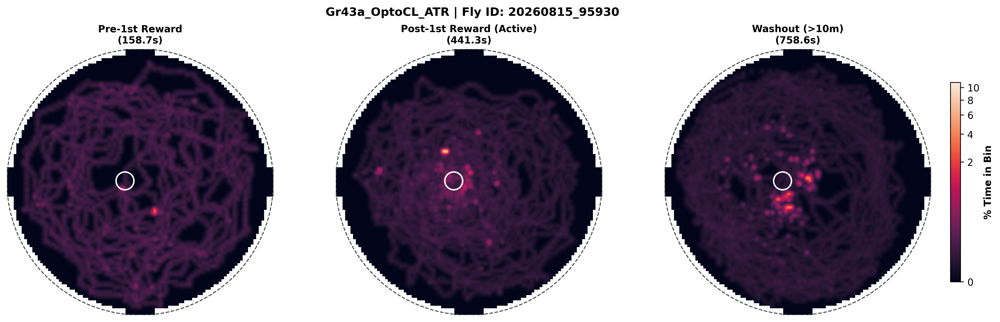

In [ ]:

# 1.a) Single Cartesian Experiment Plot
fig, ax = plot_single_experiment_cartesian_density(
    dataset=dataset_Gr43a_ATR_CL, 
    exp_idx=1, 
    dataset_name="Gr43a_OptoCL_ATR",
    
)


Error processing index 30 (20260927_161012): Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.
Loaded 37 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']


In [ ]:

fig, axes = plot_condition_psth_summary(
    datasets=[dataset_Gr5a_ATR_CL,dataset_Gr43a_ATR_CL, dataset_Gr5a_NR_CL, dataset_Gr43a_NR_CL ],
    group_names=["Gr5a_ATR" ,"Gr43a_ATR", "Gr5a_NR", "Gr43a_NR"],
    metrics=["Vf_smooth", "Vr_abs"],
    colors=["#F16237", "#0E37BB", "#C4A140", "#37CCF1"],
    title="Mean velocities aligned to reward onset"
)
plt.show()

In [ ]:
# from behavior_fw.visualization.plot_trajectory import plot_multi_experiment_split_trajectories
# Define your palette map
color_map = {
    "Baseline": "#BA90EB", 
    "Stimulus": "#F16237", 
    "Washout": '#009E73'
}

# Run the plot function across all loaded fly experiments
fig, axes = plot_multi_experiment_split_trajectories(
    dataset=dataset_Gr43a_NR_CL,      
    color_map=color_map,
    arena_r=45.0,
    fps=60.0
)

# fig.savefig("split_trajectories_by_period.svg")

In [ ]:


# 1. Set global experiment parameters
GENOTYPE = "Gr43a"
MEDIUM = "ATR"
PROTOCOL = "OptoCL"

# 2. Filter metadata consistently using these variables
df_selected_meta = select_exp_condition(
    df_metadata, 
    genotype=GENOTYPE, 
    medium=MEDIUM, 
    protocol=PROTOCOL,
    zone = "300"
)

# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset = load_experiment_dataset(df_selected_meta, fps=60.0)

print(f"Loaded {len(dataset)} flies into memory!")
print("Columns in df_track:", dataset[0]["df_track"].columns.tolist())


In [ ]:
# 3. Create global strings for titles and filenames
condition_label = f"{GENOTYPE}_{PROTOCOL}_{MEDIUM}"
fig_title = f"Trajectories: {GENOTYPE} | {PROTOCOL} | {MEDIUM}"

# 4. Color map configuration
color_map = {
    "Baseline": "#BA90EB",
    "Stimulus": "#F16237",
    "Washout": "#009E73"
}

# 5. Generate plot
fig, axes = plot_multi_experiment_split_trajectories(
    dataset=dataset,  # your dataset list corresponding to df_selected_meta
    color_map=color_map,
    fig_title=fig_title,
    arena_r=45.0,
    fps=60.0
)

# # 6. Save using the dynamic condition label
# save_filename = f"trajectories_split_{condition_label}.svg"
# fig.savefig(save_filename, bbox_inches="tight")
# print(f"Saved figure to {save_filename}")

In [ ]:
from behavior_fw.visualization.plot_multi_density import (
    plot_single_experiment_epoch_densities,
    plot_condition_epoch_densities,
    plot_compare_four_conditions_densities,
)


In [ ]:

# 1. Single Fly 3 Epochs
fig1, ax1 = plot_single_experiment_epoch_densities(dataset_Gr43a_ATR_CL[10])


In [ ]:

# 2. Condition-Wide Pooled 3 Epochs
fig2, ax2 = plot_condition_epoch_densities(dataset_Gr5a_ATR_CL, condition_name="Gr5a_ATR")


In [ ]:

# 3. All 4 Conditions Comparison (4 Rows x 3 Columns)
fig3, ax3 = plot_compare_four_conditions_densities(
    datasets=[dataset_Gr43a_ATR_CL, dataset_Gr5a_ATR_CL, dataset_Gr43a_NR_CL, dataset_Gr5a_NR_CL],
    group_names=["Gr43a ATR", "Gr5a ATR", "Gr43a NR", "Gr5a NR"],
    title="Spatial Occupancy Comparison Across Genotypes & Epochs"
)

In [ ]:
import seaborn as sns  # Ensures 'rocket' colormap is registered in matplotlib
from behavior_fw.visualization.plot_density_polar import (
    plot_compare_four_conditions_polar_densities,
)

# Define your 4 experimental condition datasets and group labels
datasets = [dataset_Gr43a_ATR_CL, dataset_Gr5a_ATR_CL, dataset_Gr43a_NR_CL, dataset_Gr5a_NR_CL]

group_names = ["Gr43a ATR", "Gr5a ATR", "Gr43a NR", "Gr5a NR"]
# Run the 4x3 polar comparison generator
fig, axes = plot_compare_four_conditions_polar_densities(
    datasets=datasets,
    group_names=group_names,
    arena_r=45.0,
    fps=60.0,
    ten_min_frames=36000,
    n_bins_r=45,
    n_bins_theta=180,
    gamma=0.3,
    cmap="rocket",
    title="Polar Spatial Occupancy Comparison Across Conditions & Epochs",
)

# Display in notebook
fig.show()

# Optional: Save for publication or poster
# fig.savefig("polar_density_comparison.pdf", bbox_inches="tight", dpi=300)

In [ ]:
from typing import Dict, List, Optional, Tuple, Any
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
import seaborn as sns
from behavior_fw.visualization.plot_density import _get_coords, _parse_reward_zone
from behavior_fw.visualization.plot_density import plot_dynamic_cartesian_densities

def plot_dynamic_cartesian_densities(
    epochs_dict: Dict[str, pd.DataFrame],
    arena_r: float = 45.0,
    n_bins: int = 100,
    gamma: float = 0.3,
    normalize_across_epochs: bool = True,
    title_prefix: str = "",
    x_col: str = "X",
    y_col: str = "Y",
    reward_zone: Optional[Dict[str, float]] = None,
    reward_zone_mm: Optional[Dict[str, float]] = None,
    **kwargs: Any,
) -> Tuple[Optional[plt.Figure], Optional[np.ndarray]]:
    """Plots 2D Cartesian spatial density (% Time in Bin) across epochs with a

    white reward zone circle.

    Parameters
    ----------
    normalize_across_epochs : bool, default=True
        If True, computes global_vmax across all epochs for fair comparison and
        renders a single shared colorbar. If False, uses local maximums
        (density_map.max()) per plot with individual colorbars.
    """
    valid_epochs = {
        k: v for k, v in epochs_dict.items() if v is not None and len(v) > 0
    }
    if not valid_epochs:
        print("No valid epoch data to plot.")
        return None, None

    # Merge reward_zone arguments
    zone_data = reward_zone or reward_zone_mm
    parsed_zone = _parse_reward_zone(zone_data)

    histograms = {}
    global_max_density = 0.0
    bin_edges = np.linspace(-arena_r, arena_r, n_bins + 1)

    # 1. Compute 2D Histograms and find global maximum
    for name, df_epoch in valid_epochs.items():
        x, y = _get_coords(df_epoch, x_col=x_col, y_col=y_col)
        counts, _, _ = np.histogram2d(x, y, bins=[bin_edges, bin_edges])

        # % time in bin
        fractional_density = (counts / len(df_epoch)) * 100.0
        histograms[name] = fractional_density.T  # Transpose for imshow alignment

        if fractional_density.max() > global_max_density:
            global_max_density = fractional_density.max()

    if global_max_density == 0:
        global_max_density = 1.0

    # 2. Render Panels
    n_panels = len(valid_epochs)
    fig, axes = plt.subplots(
        1,
        n_panels,
        figsize=(5.5 * n_panels, 5),
        dpi=300,
        layout="constrained",
    )
    if n_panels == 1:
        axes = np.array([axes])

    last_im = None

    for i, (name, density_map) in enumerate(histograms.items()):
        ax = axes[i]

        # Determine vmax based on normalization flag
        if normalize_across_epochs:
            vmax = global_max_density
        else:
            vmax = density_map.max() if density_map.max() > 0 else 1.0

        norm = colors.PowerNorm(gamma=gamma, vmin=0, vmax=vmax)

        im = ax.imshow(
            density_map,
            origin="lower",
            extent=[-arena_r, arena_r, -arena_r, arena_r],
            cmap="rocket",
            norm=norm,
            interpolation="gaussian",
        )
        last_im = im

        # Arena Border
        arena_circle = patches.Circle(
            (0, 0), arena_r, color="white", fill=False, linestyle="--", linewidth=1.2, alpha=0.6
        )
        ax.add_patch(arena_circle)

        # White Border Circle for Reward Zone
        if parsed_zone:
            zx, zy, zr = parsed_zone
            zone_circle = patches.Circle(
                (zx, zy),
                zr,
                edgecolor="white",
                facecolor="none",
                linestyle="-",
                linewidth=1.8,
                zorder=10,
            )
            ax.add_patch(zone_circle)

        # Styling
        ax.set_aspect("equal")
        ax.set_xlim(-arena_r - 2, arena_r + 2)
        ax.set_ylim(-arena_r - 2, arena_r + 2)
        ax.set_xlabel("X (mm)", fontsize=10)
        ax.set_ylabel("Y (mm)", fontsize=10)

        epoch_seconds = len(valid_epochs[name]) / 60.0
        ax.set_title(
            f"{name.replace('_', ' ')}\n({epoch_seconds:.1f} s)",
            fontsize=12,
            pad=10,
        )

        # If normalizing individually, draw local per-panel colorbar
        if not normalize_across_epochs:
            cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.03)
            cbar.set_label("% Time in Bin", fontsize=8)

    # If normalizing across epochs, draw single shared figure-wide colorbar
    if normalize_across_epochs and last_im is not None:
        cbar = fig.colorbar(last_im, ax=axes, shrink=0.75, pad=0.03)
        cbar.set_label("% Time in Bin", fontsize=10)

    if title_prefix:
        fig.suptitle(
            f"Cartesian Spatial Density - {title_prefix}", fontsize=14, y=1.05
        )

    return fig, axes

In [ ]:

# 3. All 4 Conditions Comparison (4 Rows x 3 Columns)
fig3, ax3 = plot_dynamic_cartesian_densities(
    datasets=[dataset_Gr43a_ATR_CL, dataset_Gr5a_ATR_CL, dataset_Gr43a_NR_CL, dataset_Gr5a_NR_CL],
    group_names=["Gr43a ATR", "Gr5a ATR", "Gr43a NR", "Gr5a NR"],
    title="Spatial Occupancy Comparison Across Genotypes & Epochs"
)

In [ ]:
# Imports
from behavior_fw.visualization.plot_density import (
    plot_single_experiment_cartesian_density,
    plot_dataset_average_cartesian_density,
    plot_compare_conditions_cartesian,
    plot_single_experiment_polar_density,
    plot_dataset_average_polar_density,
    plot_compare_conditions_polar,
)


In [ ]:

# 1.a) Single Cartesian Experiment Plot
fig, ax = plot_single_experiment_cartesian_density(
    dataset=dataset_Gr43a_ATR_CL, 
    exp_idx=0, 
    dataset_name="Gr43a_OptoCL_ATR"
)


In [ ]:

# 1.b) Dataset Average Cartesian Plot
fig, ax = plot_dataset_average_cartesian_density(
    dataset=dataset, 
    dataset_name="Gr43a_OptoCL_ATR"
)

# 1.c) Cartesian Comparison Across Conditions
fig, ax = plot_compare_conditions_cartesian(
    datasets=[dataset_Gr43a_ATR_CL, dataset_Gr5a_ATR_CL],
    group_names=["Gr43a_ATR", "Gr5a_ATR"],
    normalize_across_datasets=True  # Toggle ON/OFF as needed
)

# 2.a) Single Polar Experiment Plot
fig, ax = plot_single_experiment_polar_density(
    dataset=dataset, 
    exp_idx=0, 
    dataset_name="Gr43a_OptoCL_ATR"
)

# 2.b) Dataset Average Polar Plot
fig, ax = plot_dataset_average_polar_density(
    dataset=dataset, 
    dataset_name="Gr43a_OptoCL_ATR"
)

# 2.c) Polar Comparison Across Conditions
fig, ax = plot_compare_conditions_polar(
    datasets=[dataset_gr43a, dataset_gr5a],
    group_names=["Gr43a_ATR", "Gr5a_ATR"],
    normalize_across_datasets=False  # Toggle ON/OFF as needed
)